# Case Study: C-Band Transceiver

This example demonstrates the features of `gdsfactory` based on a C-Band Transceiver

## Mask Layout

### Bare Polygons
One part of strip to slot: Option 3 of https://www.flexcompute.com/tidy3d/examples/notebooks/StripToSlotConverters/

In [1]:
import gdsfactory as gf

from gf_photonics_paper import width_and_height
gf.CONF.plot_oversampling = 5.0

gf.CONF.plot_width, gf.CONF.plot_height = width_and_height(
    num_lines_code=21, 
    max_characters_per_line=37
)



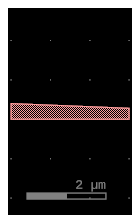

In [2]:
#| label: case-polygon

import gdsfactory as gf
from gdsfactory.gpdk import PDK
PDK.activate()

# Create a blank component 
# (essentially an empty GDS cell 
# with some special features).
c = gf.Component()

w_I, w_II, g, L = 0.4, 0.66, 0.1, 3.0

# Add some geometry to it.
polygon_taper = c.add_polygon(
    [(0, 0), (L, 0), 
     (L, (w_II-g)/2), (0, w_I)], 
    layer=PDK.layers.WG
)

c # Plot it in jupyter notebook.

### Predefined Components
Add symmetric taper and label to strip to slot

In [ ]:
gf.CONF.plot_width, gf.CONF.plot_height = width_and_height(
    num_lines_code=11, 
    max_characters_per_line=34
)

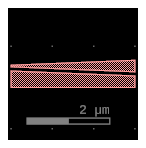

In [ ]:
#| label: case-reuse

offset = 0.75*w_II + 0.25*g
# Add a predefined symmetric taper 
t = gf.components.taper(
    length=L, 
    width1=(offset-g-w_I)*2, 
    width2=(w_II-g)/2)
t_ref = c << t
t_ref.movey(offset)
c

### Python PCells
taper of different length (autolabeled)


In [5]:
gf.CONF.plot_height = 400
gf.CONF.plot_width = 200
gf.CONF.plot_oversampling = 5.0

gf.CONF.plot_width, gf.CONF.plot_height = width_and_height(
    num_lines_code=22, 
    max_characters_per_line=81
)

In [6]:
def flip(c):
    wrapper = gf.Component()
    ref = wrapper << c
    ref.rotate(-90)
    return wrapper

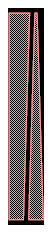

In [7]:
#| label: case-py-pcell

# The @gf.cell decorator makes this function a PCell, 
# adding caching and other features.
@gf.cell
def _strip_to_slot(
      w_I = 0.4, w_II = 0.66, g = 0.1, L = 3.0,
    ) -> gf.Component:

    c = gf.Component()
    c.add_polygon(
        [(0, 0), (L, 0), (L, (w_II-g)/2), (0, w_I)], 
        layer = PDK.layers.WG
    )

    offset = 0.75*w_II + 0.25*g
    t = gf.components.taper(length=L, width1=(offset-g-w_I)*2, width2=(w_II-g)/2)
    (c << t).movey(offset)

    return c

flip(_strip_to_slot(L=4.0)) # Flip for better visualization

### Cross Sections

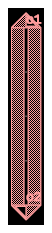

In [8]:
#| label: case-cross-section

w_rail = (w_II-g)/2
offset = (w_II+g)/4
s0 = gf.Section(width=w_II, offset=0, layer=PDK.layers.WG, 
                hidden=True, port_names=('o1', 'o2')) # Specify ports
s1 = gf.Section(width=w_rail, offset=offset,  layer=PDK.layers.WG)
s2 = gf.Section(width=w_rail, offset=-offset, layer=PDK.layers.WG)
xs_slot = gf.CrossSection(sections=(s0, s1, s2))

p = gf.path.straight(4.0)
c = gf.path.extrude(p, cross_section=xs_slot)
c.draw_ports()
flip(c)

### Ports

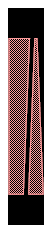

In [9]:
#| label: case-ports

@gf.cell
def strip_to_slot(
      w_I = 0.4, w_II = 0.66,
      g = 0.1, L = 3.0,
    ) -> gf.Component:

    c = gf.Component()
    c << _strip_to_slot(w_I, w_II, g, L)

    kwargs = dict(layer=PDK.layers.WG, port_type='optical')

    c.add_port(
        name='o1', width=w_I,
        orientation=180, center=(0, w_I/2),
        **kwargs
    )

    c.add_port(
        name='o2', width=w_II, cross_section=xs_slot,
        orientation=0, center=(L, w_II/2),
        **kwargs
    )

    return c

I2II = strip_to_slot()
I2II.copy().draw_ports()
flip(I2II)

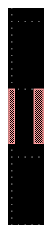

In [10]:
# TODO why does this not work?
c = gf.Component()

p = gf.path.straight(4.0)
for i, port in enumerate(I2II.ports):
  wg = gf.path.extrude(p, cross_section=port.cross_section)
  (c << wg).movey(i*2)
  wg.draw_ports()
flip(c)

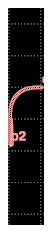

In [11]:
#| label: case-port-connect

@gf.cell
def convert_and_bend() -> gf.Component:
  c = gf.Component()
  I2II = c << strip_to_slot(L=4.0)

  bend = c << (
      gf.components.bend_euler(radius=5, width=I2II.ports["o1"].width)
  )
  bend.connect("o2", I2II.ports["o1"])

  c.add_port("o1", port=bend.ports["o1"]) #TODO: is there a more elegant solution to this?
  c.add_port("o2", port=I2II.ports["o2"])
  
  return c

c_convert_and_bend = convert_and_bend()
c_convert_and_bend.draw_ports()
flip(c_convert_and_bend)

In [12]:
#| label: case-port-pprint

c_convert_and_bend.pprint_ports()

┏━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ name ┃ width ┃ orientation ┃ layer    ┃ center      ┃ port_type ┃
┡━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ o1   │ 0.4   │ 90.0        │ WG (1/0) │ (-5.0, 5.2) │ optical   │
│ o2   │ 0.66  │ 0.0         │ WG (1/0) │ (4.0, 0.33) │ optical   │
└──────┴───────┴─────────────┴──────────┴─────────────┴───────────┘

### Routing

2026-05-09 16:33:57.730 | WARNING  | kfactory.kcell:show:3958 - Could not connect to klive server


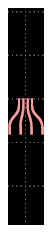

In [13]:
#| label: case-route-multiple
c = gf.Component()
I2II = strip_to_slot()
dummy = gf.components.straight(3)

converters = [c << I2II for _ in range(4)]
wgs = [c << dummy for _ in range(4)]

for i, conv in enumerate(converters):
    conv.move((13, (i-1.5)*5))

for i, wg in enumerate(wgs):
    wg.movey((i-1.5)*2)


# Automatically route a waveguide 
# between the waveguides and converters
gf.routing.route_bundle_sbend(
    c,
    ports1=[wg.ports["o2"] for wg in wgs],
    ports2=[cv.ports["o1"] for cv in converters],
    cross_section=gf.cross_section.strip,
)
c.show()
flip(c)

4 WGs to 4 stip to slot

### YAML-flow
- Pack/Grid

### Regression Tests
- Rev 1: fundamental comp -> derived component 1
- Rev 2: fundamental comp -> derived component 1 & derived component 2
- To introduce derived comp 2 the design engineer introduced changes to fundamental comp -> regression in derived comp 1 -> show GDSdiff.

## Simulation

### Component Level Optical Simulations
#### S-Parameters of a Strip to Slot Converter
#### S-Parameters of a Directional Coupler
#### S-parameters of a Grating Coupler


### Component Level Electrical and Thermal Simulations
  - Thermal Tuners
  - Modulators (travelling wave)

## Process Development Kits
  - Layer Definitions
  - Cross-sections; Layer Stack
  - Cell-library
  - Design Rules

## Design Verification
### Design Rule Check
also mention booleans and dummy fill
### Layout vs. Schematic

## Measurement and Validation
  - Metadata: Location of Fibercouplers; Measurement Schema; Wafer prober compatibility
  - Teststructures: Processcontrol; Litho/Alignment; DOE; Cutback; TLM